In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
# Load dataset
df = pd.read_csv(
    "../datasets/raw/graduate_admissions/Admission_Predict.csv"
)

# Clean column names
df.columns = df.columns.str.strip()

# Remove ID column
df = df.drop(columns=["Serial No."])

# Separate features and target
X = df.drop(columns=["Chance of Admit"])
y = df["Chance of Admit"]

# Split dataset (same split as previous phase)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Standardize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (320, 7)
Testing shape: (80, 7)


In [4]:
from sklearn.pipeline import Pipeline

degrees = [1, 2, 3, 4]

models = {}
results = []

for degree in degrees:

    model = Pipeline([
        ("poly", PolynomialFeatures(
            degree=degree,
            include_bias=False
        )),
        ("scaler", StandardScaler()),
        ("regression", LinearRegression())
    ])

    # Train the model
    model.fit(X_train_scaled, y_train)

    # Predictions
    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    # Training metrics
    train_mse = mean_squared_error(y_train, train_pred)
    train_rmse = np.sqrt(train_mse)
    train_r2 = r2_score(y_train, train_pred)

    # Testing metrics
    test_mse = mean_squared_error(y_test, test_pred)
    test_rmse = np.sqrt(test_mse)
    test_r2 = r2_score(y_test, test_pred)

    # Store model
    models[degree] = model

    # Store results
    results.append({
        "Degree": degree,
        "Train MSE": train_mse,
        "Test MSE": test_mse,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Train R2": train_r2,
        "Test R2": test_r2
    })

print("Polynomial Regression training completed!")

Polynomial Regression training completed!


In [5]:
results_df = pd.DataFrame(results)

display(results_df.round(5))

,Degree,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2
0,1,0.00387,0.00462,0.06221,0.06795,0.79519,0.82121
1,2,0.00346,0.00451,0.05880,0.06715,0.81704,0.82538
2,3,0.00253,0.01069,0.05031,0.10338,0.86606,0.58615
3,4,0.00021,0.87718,0.01443,0.93658,0.98898,-32.96851


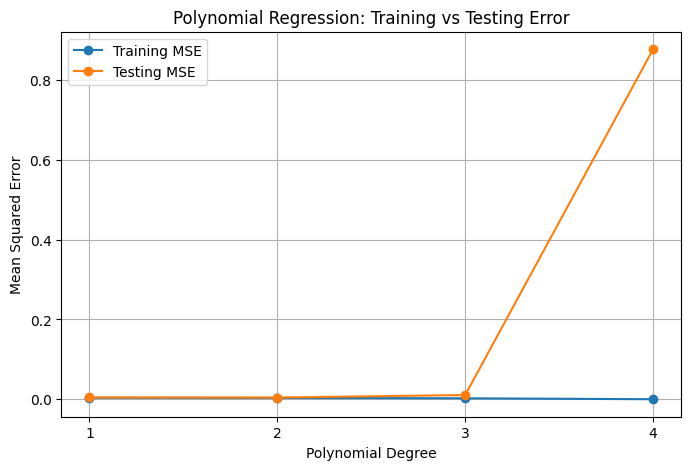

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Degree"],
    results_df["Train MSE"],
    marker="o",
    label="Training MSE"
)

plt.plot(
    results_df["Degree"],
    results_df["Test MSE"],
    marker="o",
    label="Testing MSE"
)

plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.title("Polynomial Regression: Training vs Testing Error")

plt.xticks(degrees)
plt.legend()
plt.grid(True)

plt.show()

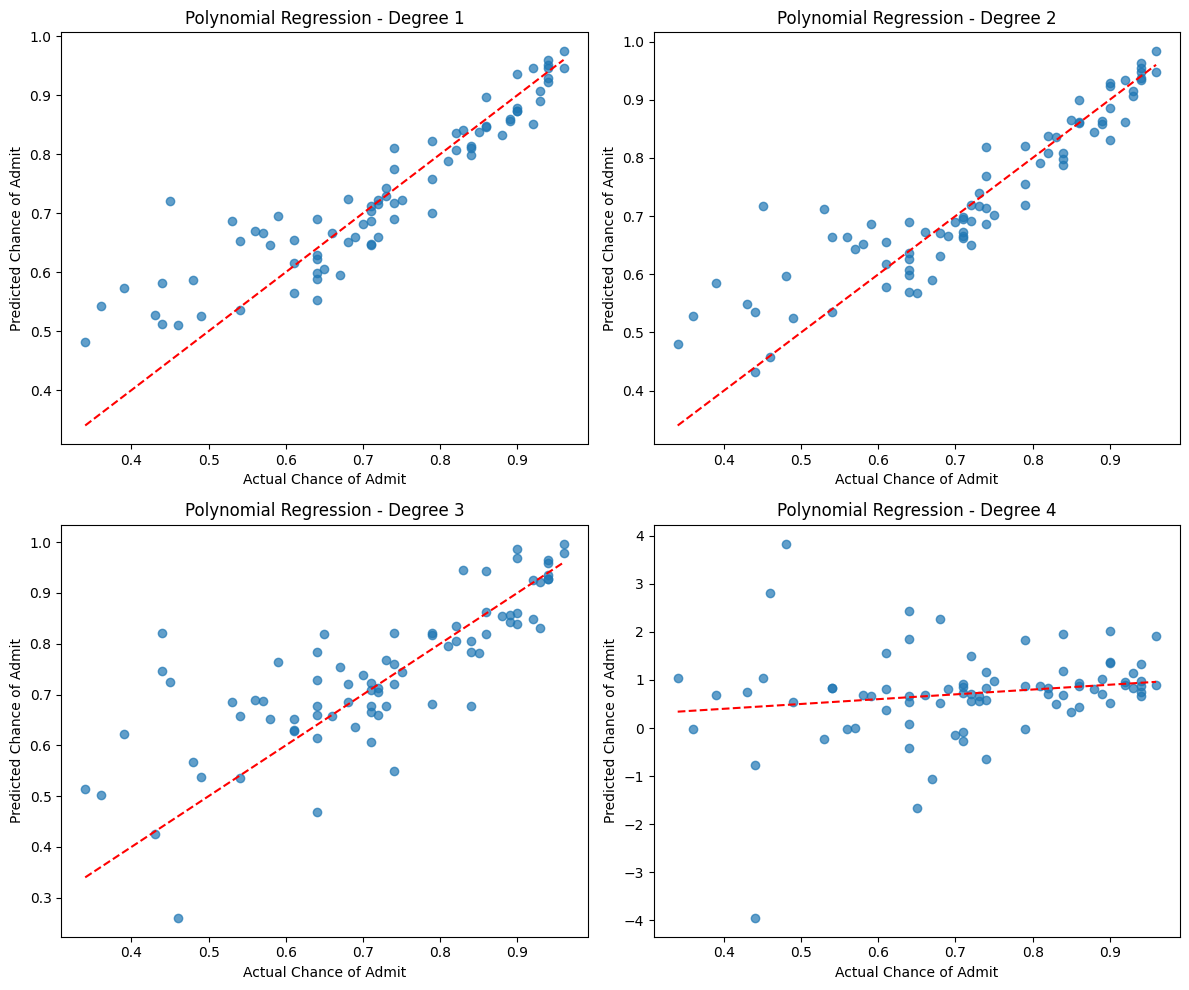

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, degree in zip(axes.flatten(), degrees):

    y_pred = models[degree].predict(X_test_scaled)

    ax.scatter(y_test, y_pred, alpha=0.7)

    ax.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        "r--"
    )

    ax.set_title(f"Polynomial Regression - Degree {degree}")
    ax.set_xlabel("Actual Chance of Admit")
    ax.set_ylabel("Predicted Chance of Admit")

plt.tight_layout()
plt.show()